In [ ]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)


In [ ]:
input_path = Path("/content/Afficionado Coffee Roasters.xlsx - Transactions (1).csv")
if not input_path.exists():
    raise FileNotFoundError("Upload Afficionado Coffee Roasters.xlsx to the Colab session first.")
raw_df = pd.read_csv(input_path)
print("Rows and columns", raw_df.shape)
print(raw_df.head())

Rows and columns (149116, 11)
   transaction_id  year transaction_time  transaction_qty  store_id  \
0               1  2025          7:06:11                2         5   
1               2  2025          7:08:56                2         5   
2               3  2025          7:14:04                2         5   
3               4  2025          7:20:24                1         5   
4               5  2025          7:22:41                2         5   

    store_location  product_id  unit_price    product_category  \
0  Lower Manhattan          32         3.0              Coffee   
1  Lower Manhattan          57         3.1                 Tea   
2  Lower Manhattan          59         4.5  Drinking Chocolate   
3  Lower Manhattan          22         2.0              Coffee   
4  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail  
0  Gourmet brewed coffee                  Ethiopia Rg  
1        Brewed Chai tea     Spicy

In [ ]:
analysis_df = raw_df.copy()
for col_name in ["transaction_id", "year", "transaction_qty", "store_id", "product_id"]:
    analysis_df[col_name] = pd.to_numeric(analysis_df[col_name], errors="coerce")
analysis_df["unit_price"] = pd.to_numeric(analysis_df["unit_price"], errors="coerce")
analysis_df["transaction_time"] = analysis_df["transaction_time"].astype(str).str.strip()
analysis_df["transaction_datetime"] = pd.to_datetime(analysis_df["year"].astype("Int64").astype(str) + " " + analysis_df["transaction_time"], format="%Y %H:%M:%S", errors="coerce")
analysis_df['transaction_date'] = analysis_df['transaction_datetime'].dt.date
analysis_df["hour"] = analysis_df["transaction_datetime"].dt.hour
analysis_df["minute"] = analysis_df["transaction_datetime"].dt.minute
analysis_df["daypart"] = pd.cut(analysis_df["hour"], bins=[-1, 5, 10, 13, 17, 23], labels=["Overnight", "Morning Rush", "Lunch", "Afternoon", "Evening"])
analysis_df["revenue"] = analysis_df["transaction_qty"] * analysis_df["unit_price"]
analysis_df = analysis_df.drop_duplicates("transaction_id").dropna(subset=["transaction_id", "transaction_datetime", "transaction_qty", "unit_price"])
print(analysis_df.head())
print("Clean rows", len(analysis_df))

   transaction_id  year transaction_time  transaction_qty  store_id  \
0               1  2025          7:06:11                2         5   
1               2  2025          7:08:56                2         5   
2               3  2025          7:14:04                2         5   
3               4  2025          7:20:24                1         5   
4               5  2025          7:22:41                2         5   

    store_location  product_id  unit_price    product_category  \
0  Lower Manhattan          32         3.0              Coffee   
1  Lower Manhattan          57         3.1                 Tea   
2  Lower Manhattan          59         4.5  Drinking Chocolate   
3  Lower Manhattan          22         2.0              Coffee   
4  Lower Manhattan          57         3.1                 Tea   

            product_type               product_detail transaction_datetime  \
0  Gourmet brewed coffee                  Ethiopia Rg  2025-01-01 07:06:11   
1        Brewed Chai

In [ ]:
quality_df = pd.DataFrame({"missing_values": analysis_df.isna().sum(), "missing_percent": analysis_df.isna().mean().mul(100).round(2)}).sort_values("missing_values", ascending=False)
print(quality_df.head(15))

                      missing_values  missing_percent
transaction_id                     0              0.0
year                               0              0.0
transaction_time                   0              0.0
transaction_qty                    0              0.0
store_id                           0              0.0
store_location                     0              0.0
product_id                         0              0.0
unit_price                         0              0.0
product_category                   0              0.0
product_type                       0              0.0
product_detail                     0              0.0
transaction_datetime               0              0.0
transaction_date                   0              0.0
hour                               0              0.0
minute                             0              0.0


In [8]:
kpi_df = pd.DataFrame({"metric": ["Revenue", "Quantity", "Transactions", "Average transaction value"], "value": [analysis_df["revenue"].sum(), analysis_df["transaction_qty"].sum(), analysis_df["transaction_id"].nunique(), analysis_df["revenue"].mean()]})
print(kpi_df)

                      metric          value
0                    Revenue  698812.330000
1                   Quantity  214470.000000
2               Transactions  149116.000000
3  Average transaction value       4.686367


In [9]:
store_summary = analysis_df.groupby(["store_id", "store_location"], as_index=False).agg(transactions=("transaction_id", "nunique"), quantity=("transaction_qty", "sum"), revenue=("revenue", "sum"), avg_transaction_value=("revenue", "mean")).sort_values("revenue", ascending=False)
category_summary = analysis_df.groupby("product_category", as_index=False).agg(transactions=("transaction_id", "nunique"), quantity=("transaction_qty", "sum"), revenue=("revenue", "sum")).sort_values("revenue", ascending=False)
print(store_summary)
print(category_summary)

   store_id   store_location  transactions  quantity    revenue  \
2         8   Hell's Kitchen         50735     71737  236511.17   
0         3          Astoria         50599     70991  232243.91   
1         5  Lower Manhattan         47782     71742  230057.25   

   avg_transaction_value  
2               4.661696  
0               4.589891  
1               4.814726  
     product_category  transactions  quantity    revenue
2              Coffee         58416     89250  269952.45
8                 Tea         45449     69737  196405.95
0              Bakery         22796     23214   82315.64
4  Drinking Chocolate         11468     17457   72416.00
3        Coffee beans          1753      1828   40085.25
1             Branded           747       776   13607.00
6           Loose Tea          1210      1210   11213.60
5            Flavours          6790     10511    8408.80
7  Packaged Chocolate           487       487    4407.64


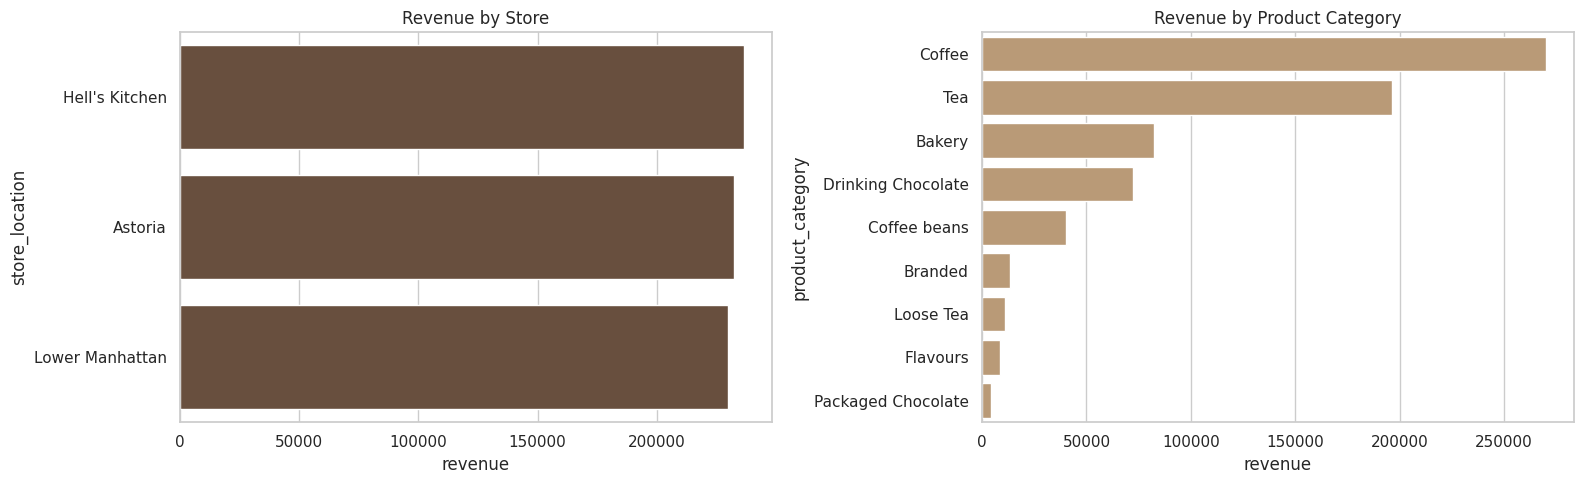

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=store_summary, x="revenue", y="store_location", ax=axes[0], color="#6f4e37")
axes[0].set_title("Revenue by Store")
sns.barplot(data=category_summary, x="revenue", y="product_category", ax=axes[1], color="#c49a6c")
axes[1].set_title("Revenue by Product Category")
plt.tight_layout()
plt.show()

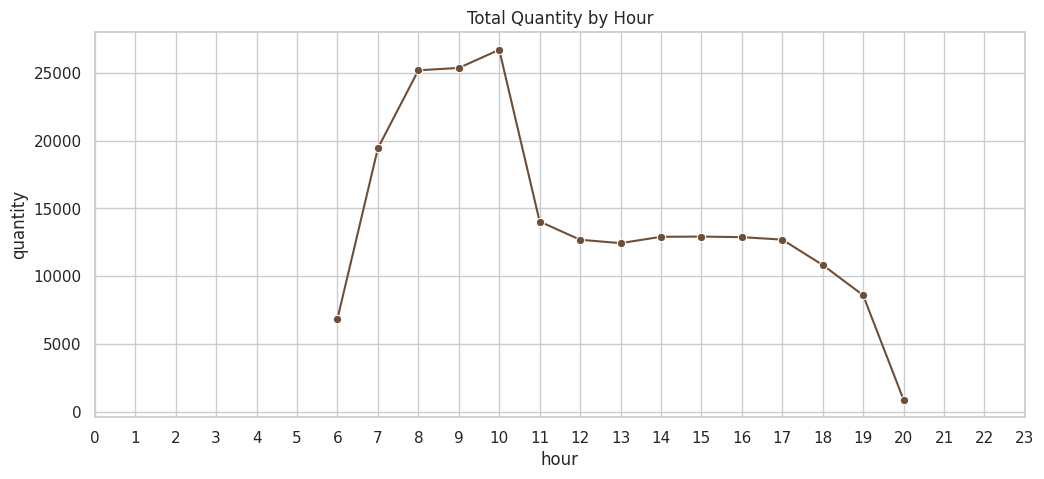

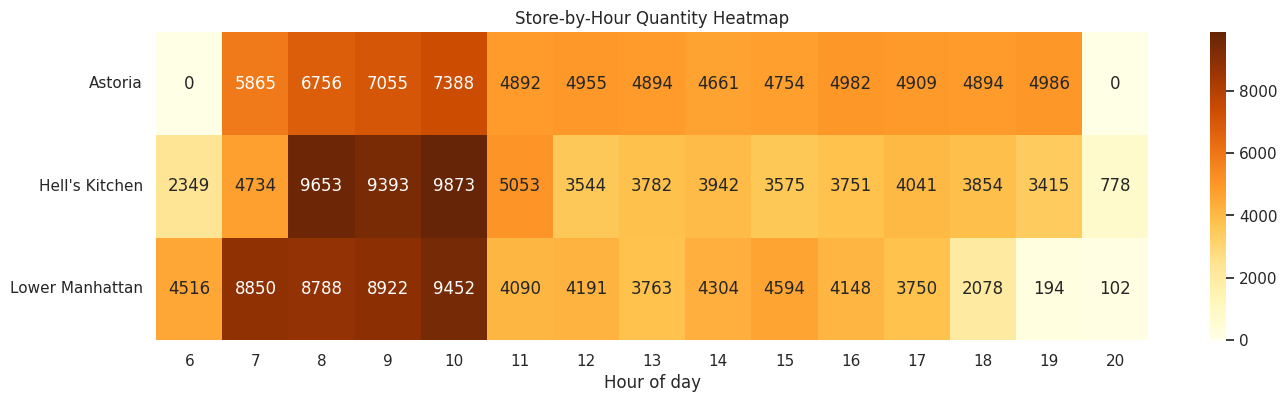

In [11]:
hourly_store = analysis_df.groupby(["store_id", "store_location", "hour", "daypart"], as_index=False, observed=True).agg(transactions=("transaction_id", "nunique"), quantity=("transaction_qty", "sum"), revenue=("revenue", "sum"), avg_unit_price=("unit_price", "mean"))
hourly_store["quantity_per_transaction"] = hourly_store["quantity"] / hourly_store["transactions"]
hourly_total = hourly_store.groupby("hour", as_index=False).agg(quantity=("quantity", "sum"), revenue=("revenue", "sum"), transactions=("transactions", "sum"))
plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_total, x="hour", y="quantity", marker="o", color="#6f4e37")
plt.title("Total Quantity by Hour")
plt.xticks(range(24))
plt.show()
heatmap_df = hourly_store.pivot_table(index="store_location", columns="hour", values="quantity", aggfunc="sum", fill_value=0)
plt.figure(figsize=(16, 4))
sns.heatmap(heatmap_df, cmap="YlOrBr", annot=True, fmt=".0f")
plt.title("Store-by-Hour Quantity Heatmap")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.show()

In [12]:
store_thresholds = hourly_store.groupby("store_location")["quantity"].transform(lambda s: s.quantile(0.75))
hourly_store["is_peak_hour"] = hourly_store["quantity"] >= store_thresholds
peak_hours = hourly_store[hourly_store["is_peak_hour"]].sort_values(["store_location", "quantity"], ascending=[True, False])
print(peak_hours.head(20))

    store_id   store_location  hour       daypart  transactions  quantity  \
3          3          Astoria    10  Morning Rush          5291      7388   
2          3          Astoria     9  Morning Rush          5083      7055   
1          3          Astoria     8  Morning Rush          4966      6756   
0          3          Astoria     7  Morning Rush          4181      5865   
32         8   Hell's Kitchen    10  Morning Rush          6957      9873   
30         8   Hell's Kitchen     8  Morning Rush          6909      9653   
31         8   Hell's Kitchen     9  Morning Rush          6767      9393   
33         8   Hell's Kitchen    11         Lunch          3598      5053   
17         5  Lower Manhattan    10  Morning Rush          6297      9452   
16         5  Lower Manhattan     9  Morning Rush          5914      8922   
14         5  Lower Manhattan     7  Morning Rush          5792      8850   
15         5  Lower Manhattan     8  Morning Rush          5779      8788   

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_df = analysis_df[["transaction_qty", "unit_price", "hour", "minute", "store_location", "product_category", "product_type"]].dropna().sort_values(["hour", "minute"]).reset_index(drop=True)
cutoff = int(len(model_df) * 0.8)
train_df = model_df.iloc[:cutoff]
test_df = model_df.iloc[cutoff:]
feature_cols = ["unit_price", "hour", "minute", "store_location", "product_category", "product_type"]
cat_cols = ["store_location", "product_category", "product_type"]
num_cols = ["unit_price", "hour", "minute"]
preprocessor = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols), ("num", "passthrough", num_cols)])
model_pipeline = Pipeline([("prep", preprocessor), ("model", HistGradientBoostingRegressor(max_iter=150, random_state=42))])
model_pipeline.fit(train_df[feature_cols], train_df["transaction_qty"])
pred_qty = model_pipeline.predict(test_df[feature_cols])
print("MAE", round(mean_absolute_error(test_df["transaction_qty"], pred_qty), 4))
print("RMSE", round(mean_squared_error(test_df["transaction_qty"], pred_qty) ** 0.5, 4))

MAE 0.4365
RMSE 0.4899


In [14]:
if "transaction_date" not in analysis_df.columns:
    print("Daily forecasting is not run because transaction_date is missing from the analysis_df.")
    print("Add a real calendar date, then aggregate by date and store before applying lag and rolling features.")
else:
    analysis_df["transaction_date"] = pd.to_datetime(analysis_df["transaction_date"], errors="coerce")
    daily_store = analysis_df.groupby(["transaction_date", "store_location"], as_index=False).agg(quantity=("transaction_qty", "sum"), revenue=("revenue", "sum"))
    print(daily_store.head())

  transaction_date   store_location  quantity    revenue
0       2025-01-01          Astoria     70991  232243.91
1       2025-01-01   Hell's Kitchen     71737  236511.17
2       2025-01-01  Lower Manhattan     71742  230057.25


In [15]:
export_dir = Path("afficionado_project_outputs")
export_dir.mkdir(exist_ok=True)
analysis_df.to_csv(export_dir / "transactions_clean.csv", index=False)
hourly_store.to_csv(export_dir / "hourly_store_demand.csv", index=False)
store_summary.to_csv(export_dir / "store_summary.csv", index=False)
category_summary.to_csv(export_dir / "category_summary.csv", index=False)
peak_hours.to_csv(export_dir / "peak_hours.csv", index=False)
print("Exported files", sorted(p.name for p in export_dir.glob("*.csv")))

Exported files ['category_summary.csv', 'hourly_store_demand.csv', 'peak_hours.csv', 'store_summary.csv', 'transactions_clean.csv']
